### EXPERIMENT 1: BINARY SET OPERATIONS

Objective: Demonstrate set operations using binary images.

Tasks:
 1. Construct two overlapping binary objects.
 2. Apply union, intersection, complement, and difference.
 3. Compare the resulting binary images.

Question: How do set operations relate to logical operations?



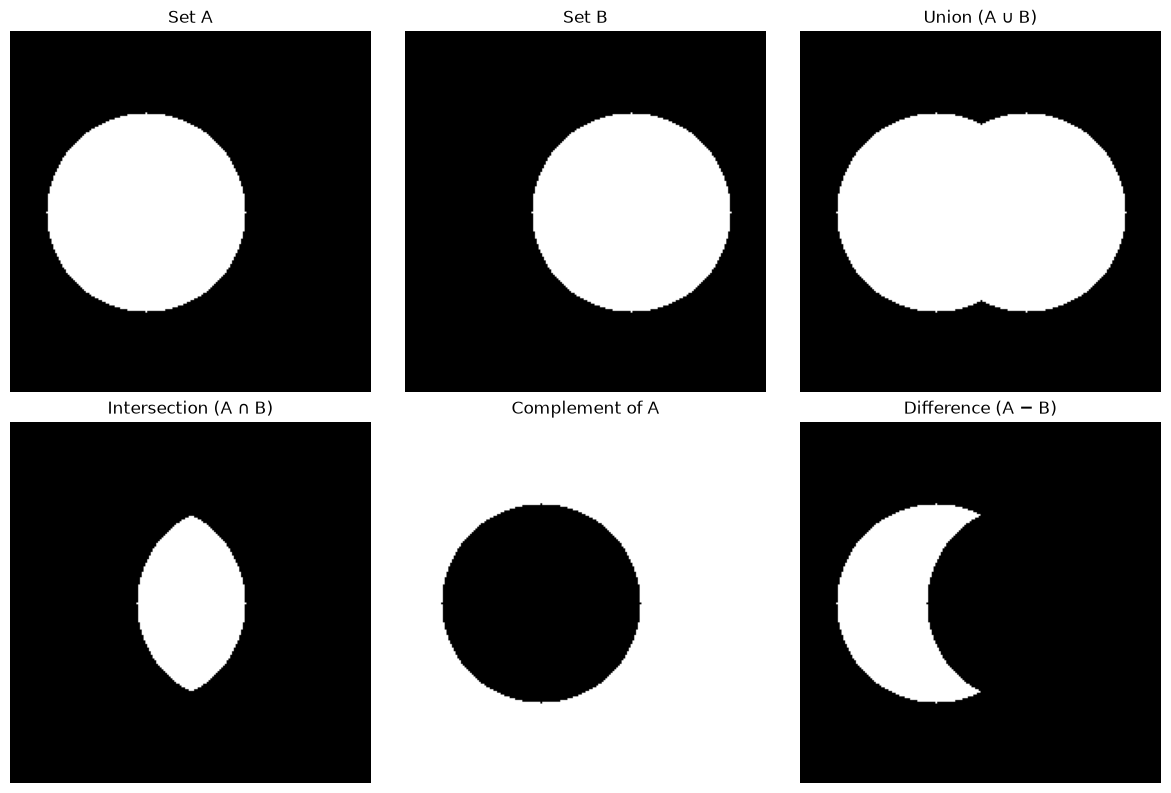

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Y, X = np.ogrid[:200, :200]

A = (X - 75)**2 + (Y - 100)**2 <= 55**2
B = (X - 125)**2 + (Y - 100)**2 <= 55**2

images = [
    A, B,
    A | B,
    A & B,
    ~A,
    A & ~B
]

titles = [
    "Set A", "Set B",
    "Union (A ∪ B)", "Intersection (A ∩ B)",
    "Complement of A", "Difference (A − B)"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 2: STRUCTURING ELEMENTS

Objective: Investigate different structuring element shapes.

Tasks:
 1. Construct square, disk, cross, and rectangular SEs.
 2. Visualize their binary matrices.
 3. Compare their shapes and dimensions.

Question: Why is the structuring element's origin important?



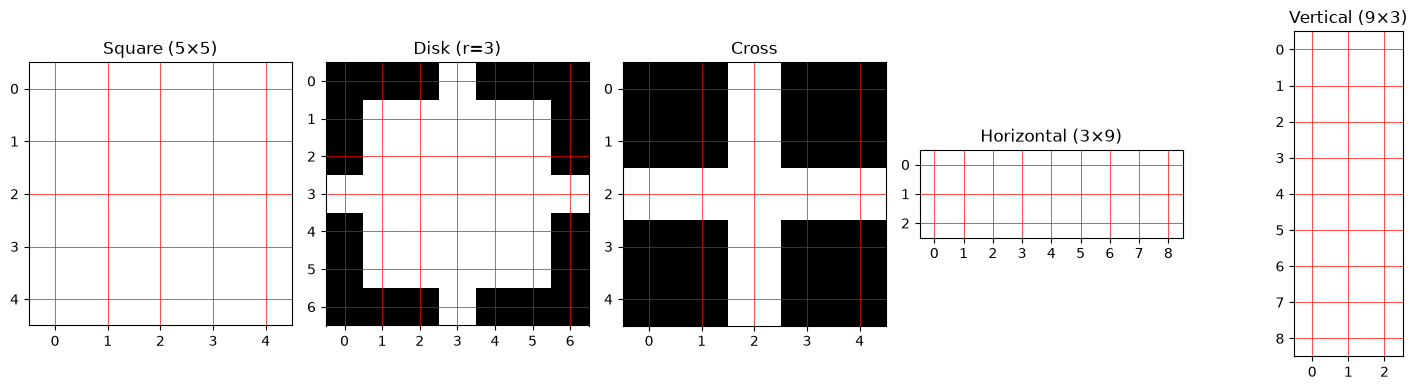

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import disk, square, rectangle

square_se = np.ones((5, 5), dtype=bool)
disk_se = disk(3)

cross_se = np.array([
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 1, 1],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0]
], dtype=bool)

horizontal_se = np.ones((3, 9), dtype=bool)
vertical_se = np.ones((9, 3), dtype=bool)

elements = [
    square_se, disk_se, cross_se,
    horizontal_se, vertical_se
]

titles = [
    "Square (5×5)", "Disk (r=3)", "Cross",
    "Horizontal (3×9)", "Vertical (9×3)"
]

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, se, title in zip(axes, elements, titles):
    ax.imshow(se, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(np.arange(se.shape[1]))
    ax.set_yticks(np.arange(se.shape[0]))
    ax.grid(color="red", linewidth=0.5)

plt.tight_layout()
plt.show()

### EXPERIMENT 3: BINARY DILATION

Objective: Investigate object expansion using different SEs.

Tasks:
 1. Construct a binary image containing a rectangle.
 2. Apply dilation using different structuring elements.
 3. Compare the resulting shapes.

Question: How do SE size and orientation affect dilation?



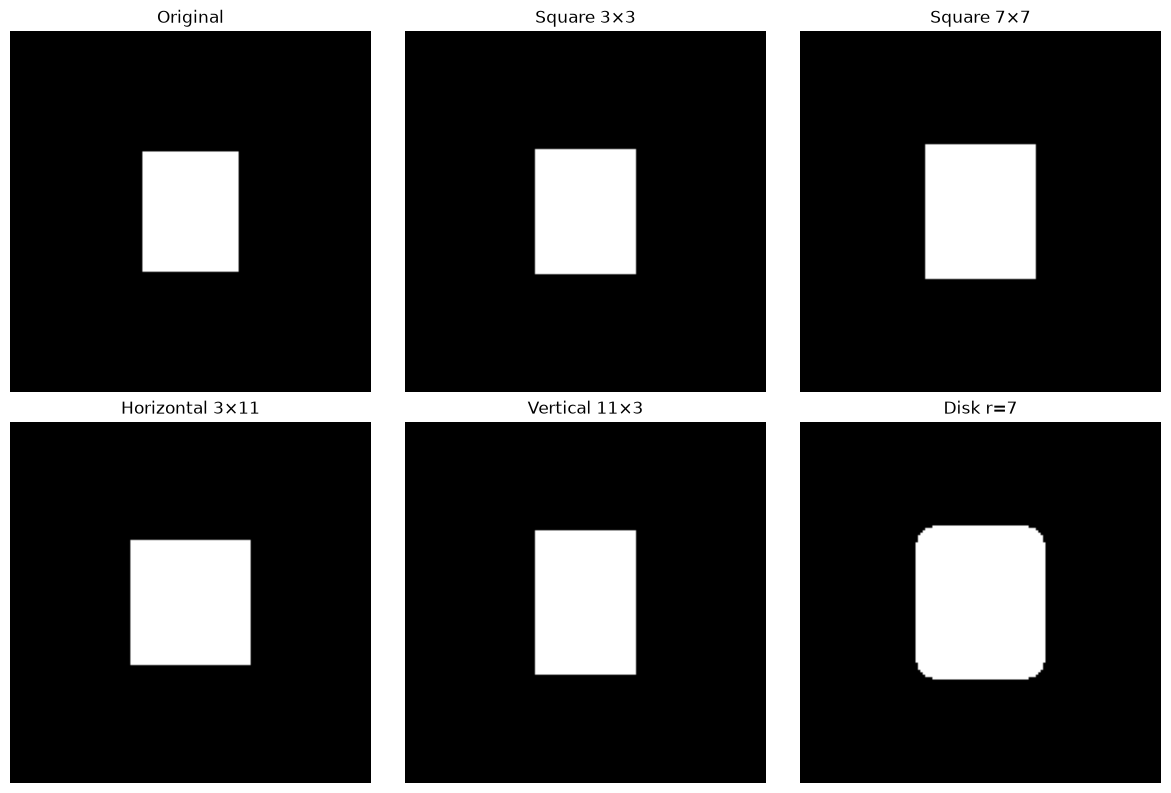

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import dilation, disk

img = np.zeros((150, 150), dtype=bool)
img[50:100, 55:95] = True

elements = [
    np.ones((3, 3), dtype=bool),
    np.ones((7, 7), dtype=bool),
    np.ones((3, 11), dtype=bool),
    np.ones((11, 3), dtype=bool),
    disk(7)
]

titles = [
    "Square 3×3", "Square 7×7",
    "Horizontal 3×11", "Vertical 11×3",
    "Disk r=7"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes.flat[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes.flat[0].set_title("Original")

for ax, se, title in zip(axes.flat[1:], elements, titles):
    result = dilation(img, footprint=se)

    ax.imshow(result, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 4: BINARY EROSION

Objective: Investigate object shrinking using different SEs.

Tasks:
 1. Construct a binary image containing a rectangle.
 2. Apply erosion using different structuring elements.
 3. Compare the resulting shapes.

Question: Why can erosion completely remove small objects?



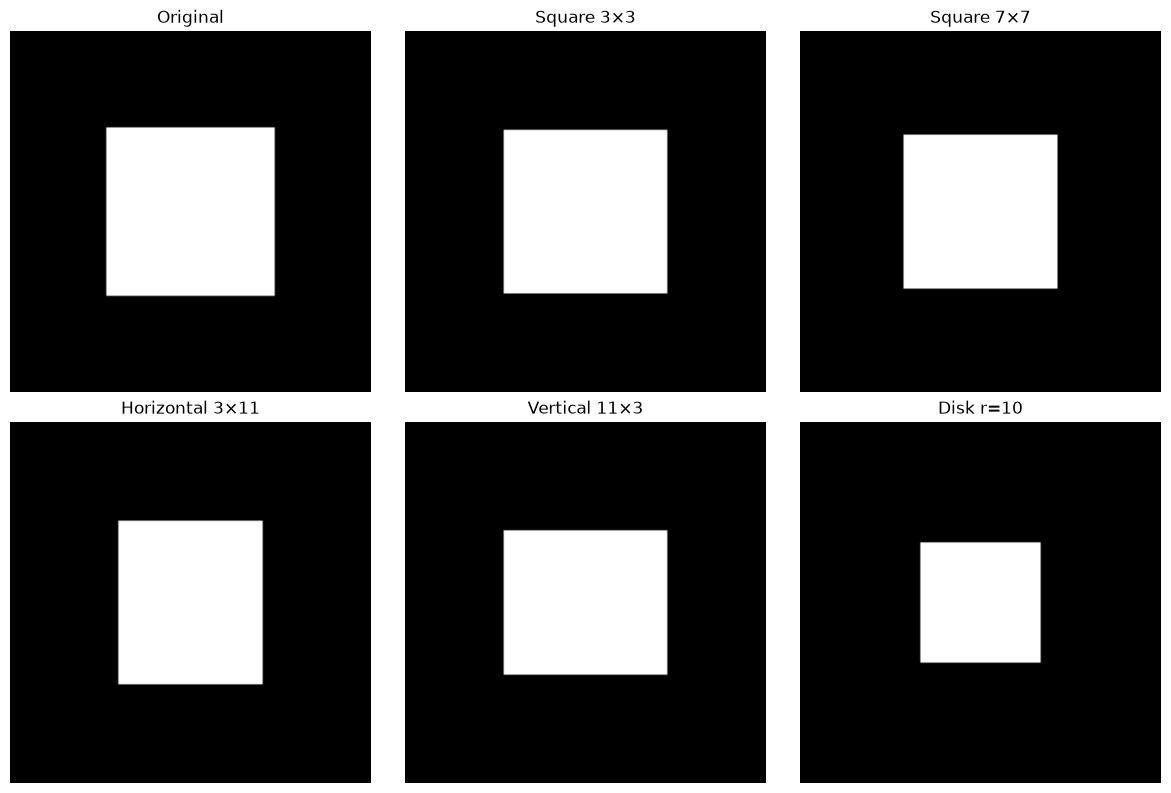

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import erosion, disk

img = np.zeros((150, 150), dtype=bool)
img[40:110, 40:110] = True

elements = [
    np.ones((3, 3), dtype=bool),
    np.ones((7, 7), dtype=bool),
    np.ones((3, 11), dtype=bool),
    np.ones((11, 3), dtype=bool),
    disk(10)
]

titles = [
    "Square 3×3", "Square 7×7",
    "Horizontal 3×11", "Vertical 11×3",
    "Disk r=10"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes.flat[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes.flat[0].set_title("Original")

for ax, se, title in zip(axes.flat[1:], elements, titles):
    result = erosion(img, footprint=se)

    ax.imshow(result, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 5: MORPHOLOGICAL OPENING

Objective: Demonstrate removal of small foreground objects.

Tasks:
 1. Construct a binary image containing large objects and small noise.
 2. Apply erosion followed by dilation.
 3. Compare manual opening with the built-in opening function.

Question: Why does opening remove small objects while preserving larger ones?



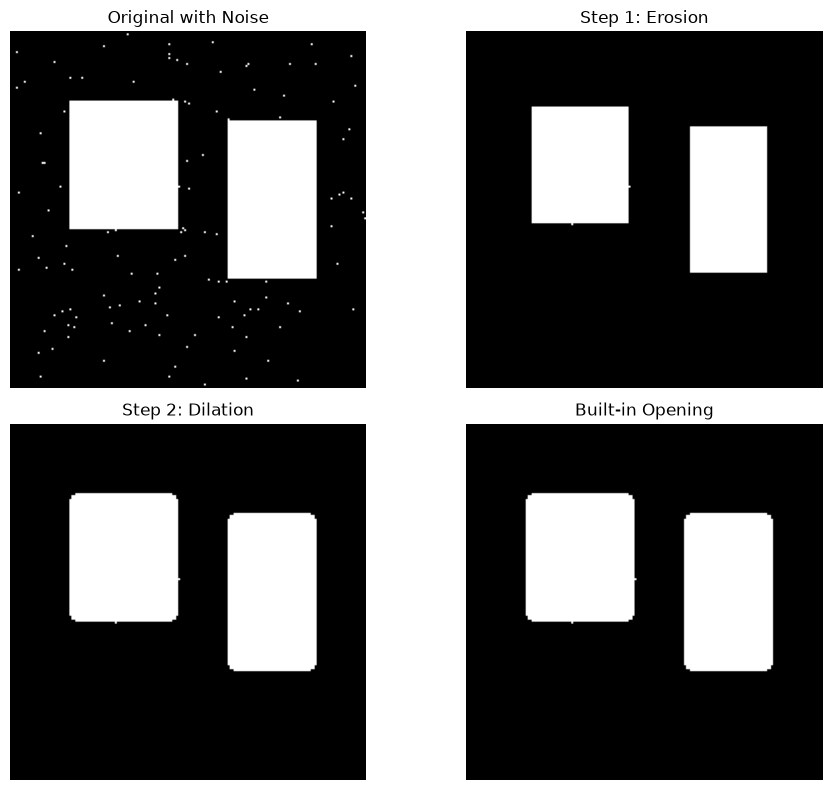

Manual and built-in results match: True


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import (
    erosion, dilation, opening, disk
)

img = np.zeros((180, 180), dtype=bool)

img[35:100, 30:85] = True
img[45:125, 110:155] = True

rng = np.random.default_rng(42)

# Add isolated foreground pixels
ys = rng.integers(0, 180, 150)
xs = rng.integers(0, 180, 150)
img[ys, xs] = True

se = disk(3)

eroded = erosion(img, footprint=se)
manual_opening = dilation(eroded, footprint=se)
built_in_opening = opening(img, footprint=se)

images = [img, eroded, manual_opening, built_in_opening]
titles = [
    "Original with Noise",
    "Step 1: Erosion",
    "Step 2: Dilation",
    "Built-in Opening"
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Manual and built-in results match:",
      np.array_equal(manual_opening, built_in_opening))

### EXPERIMENT 6: MORPHOLOGICAL CLOSING

Objective: Demonstrate filling of small holes and narrow gaps.

Tasks:
 1. Construct a binary image containing holes and a narrow gap.
 2. Apply dilation followed by erosion.
 3. Compare manual closing with the built-in function.

Question: Why does closing fill small holes without filling every hole?



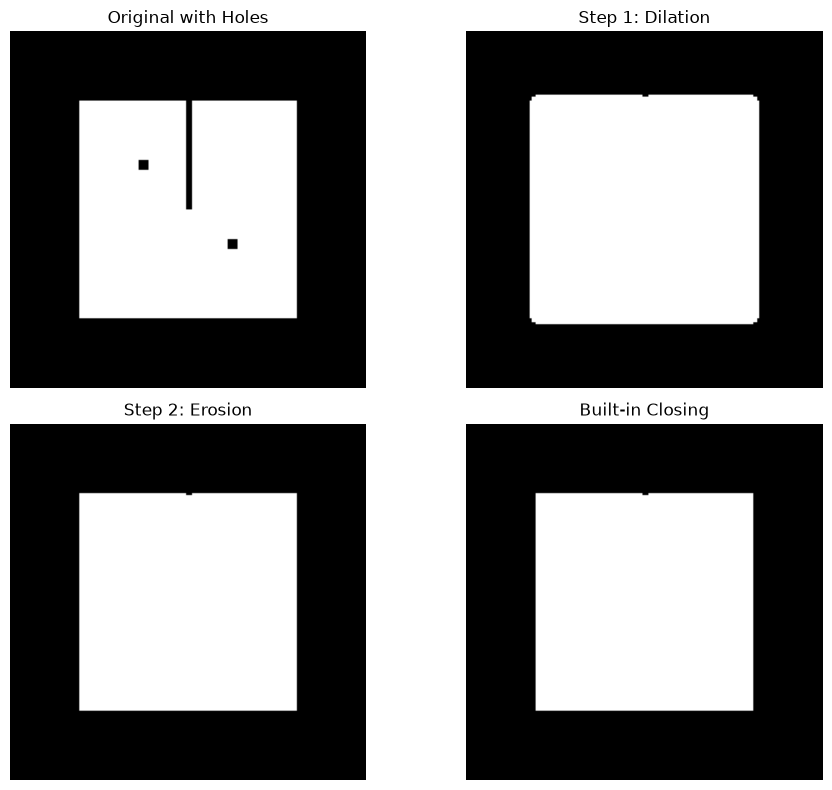

Manual and built-in results match: True


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import (
    dilation, erosion, closing, disk
)

img = np.zeros((180, 180), dtype=bool)

img[35:145, 35:145] = True

# Create small holes
img[65:70, 65:70] = False
img[105:110, 110:115] = False

# Create a narrow gap
img[35:90, 89:92] = False

se = disk(3)

dilated = dilation(img, footprint=se)
manual_closing = erosion(dilated, footprint=se)
built_in_closing = closing(img, footprint=se)

images = [img, dilated, manual_closing, built_in_closing]
titles = [
    "Original with Holes",
    "Step 1: Dilation",
    "Step 2: Erosion",
    "Built-in Closing"
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Manual and built-in results match:",
      np.array_equal(manual_closing, built_in_closing))

### EXPERIMENT 7: OPENING AND CLOSING PROPERTIES

Objective: Verify idempotence and compare compound operations.

Tasks:
 1. Apply opening and closing twice.
 2. Verify their idempotence.
 3. Compare opening followed by closing with closing followed by opening.

Question: Why does changing the order of opening and closing affect the result?



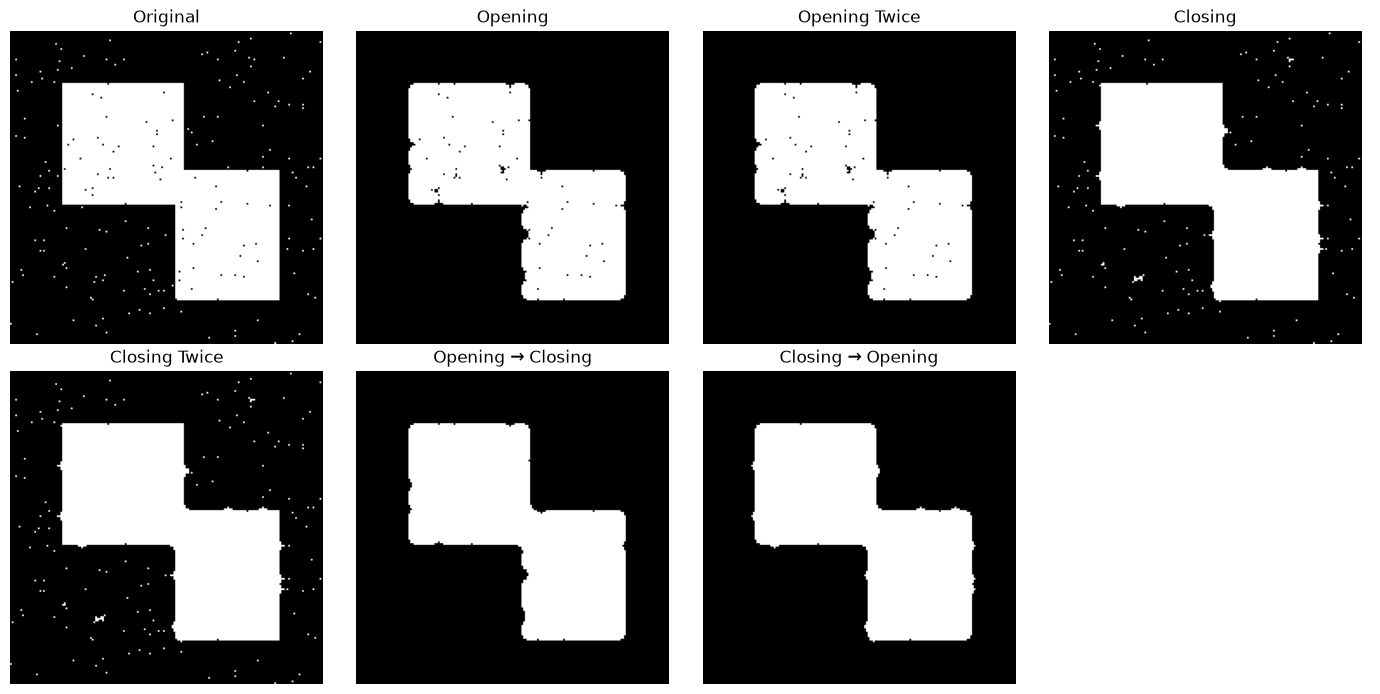

Opening is idempotent: True
Closing is idempotent: True


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import binary_opening, binary_closing, disk, opening, closing

rng = np.random.default_rng(42)

img = np.zeros((180, 180), dtype=bool)
img[30:100, 30:100] = True
img[80:155, 95:155] = True

# Foreground and background noise
ys = rng.integers(0, 180, 200)
xs = rng.integers(0, 180, 200)
img[ys, xs] = ~img[ys, xs]

se = disk(3)

opened = opening(img, footprint=se)
opened_twice = opening(opened, footprint=se)

closed = closing(img, footprint=se)
closed_twice = closing(closed, footprint=se)

open_then_close = closing(opened, footprint=se)
close_then_open = opening(closed, footprint=se)

images = [
    img, opened, opened_twice,
    closed, closed_twice,
    open_then_close, close_then_open
]

titles = [
    "Original",
    "Opening",
    "Opening Twice",
    "Closing",
    "Closing Twice",
    "Opening → Closing",
    "Closing → Opening"
]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

print("Opening is idempotent:",
      np.array_equal(opened, opened_twice))

print("Closing is idempotent:",
      np.array_equal(closed, closed_twice))

### EXPERIMENT 8: MORPHOLOGICAL BOUNDARY EXTRACTION

Objective: Extract object boundaries using morphological erosion.

Tasks:
 1. Construct a binary image.
 2. Erode the image using a structuring element.
 3. Subtract the eroded image from the original.
 4. Investigate how SE size affects boundary thickness.

Question: Why does increasing the SE size produce thicker boundaries?



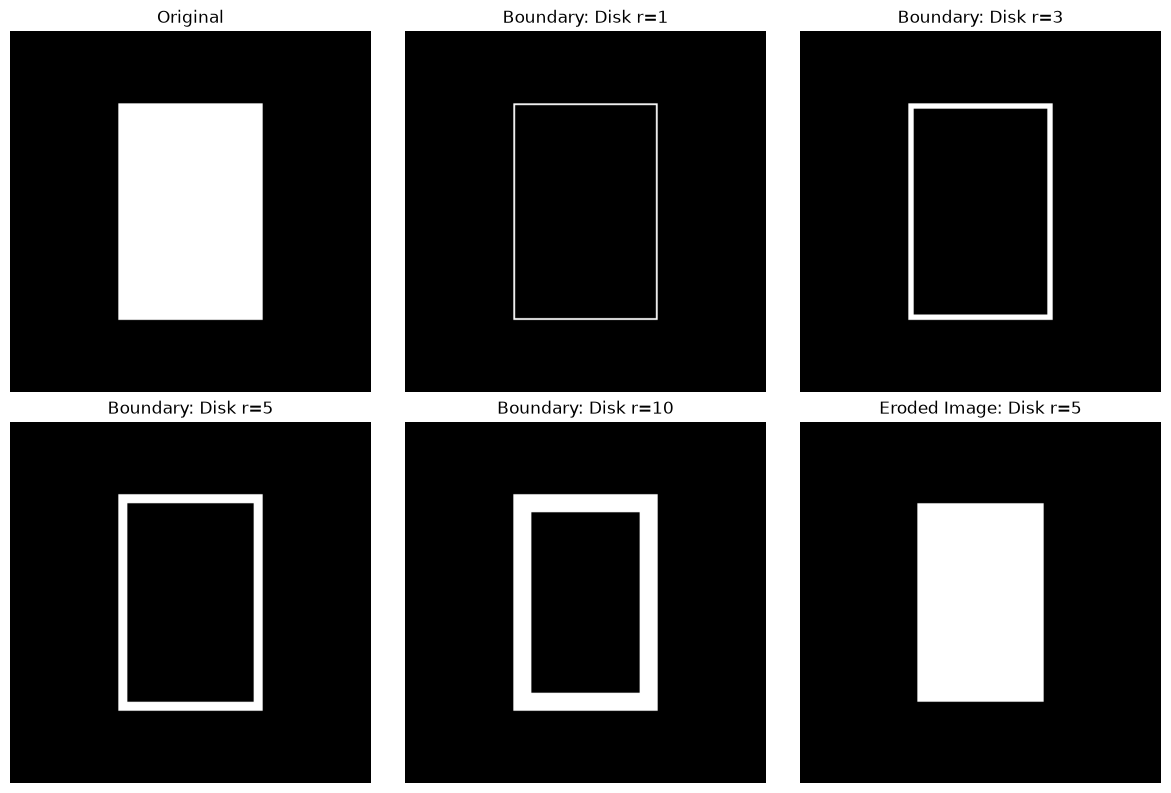

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import erosion, disk

img = np.zeros((200, 200), dtype=bool)
img[40:160, 60:140] = True

radii = [1, 3, 5, 10]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes.flat[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes.flat[0].set_title("Original")

for ax, radius in zip(axes.flat[1:5], radii):
    se = disk(radius)

    eroded = erosion(img, footprint=se)
    boundary = img & ~eroded

    ax.imshow(boundary, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Boundary: Disk r={radius}")

axes.flat[5].imshow(
    erosion(img, footprint=disk(5)),
    cmap="gray", vmin=0, vmax=1
)
axes.flat[5].set_title("Eroded Image: Disk r=5")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()